13/8192 1/33554432
22369621/33554432
Combinatorial: 22369621/33554432
Recurrence:    22369621/33554432
Decimal:       0.6666666567325592
Difference from 2/3: 1/100663296


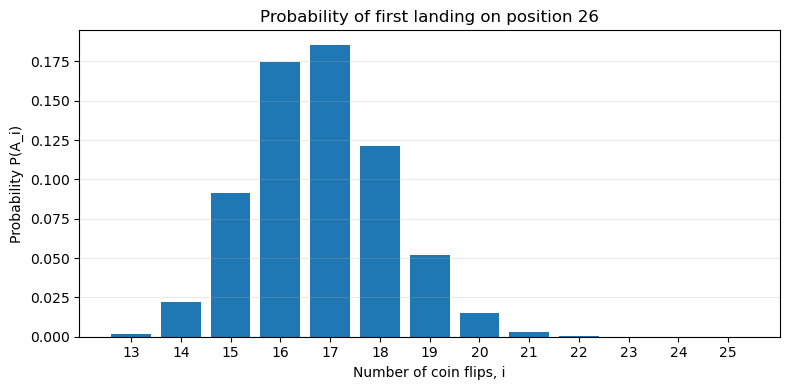

In [1]:
from math import comb
from fractions import Fraction
import matplotlib.pyplot as plt


def p(i,target=26): #P(A_i)
    target -= 1
    return Fraction(comb(i,target-i), 2**i)
print(p(13),p(25))

def p_sum( target=26):  #P(A) but hard coded for range of 13 to 25 inclusive
    return sum(
        p(i, target)
        for i in range(13, 26)
    )
    
print(p_sum())


def recurrence():
    q = [Fraction(1), Fraction(1, 2)]

    for d in range(2, 26):
        q.append((q[d-1] + q[d-2]) / 2)

    p_recurrence = q[25]

    assert p_sum() == p_recurrence

    print("Combinatorial:", p_sum())
    print("Recurrence:   ", p_recurrence)
    print("Decimal:      ", float(p_sum()))
    print("Difference from 2/3:",
        Fraction(2, 3) - p_sum())
    # at position 26 after exactly i flips
    flips = list(range(13, 26))
    probabilities = [
        comb(i, 25-i) / 2**i
        for i in flips
    ]
    
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(flips, probabilities)
    
    ax.set_xlabel("Number of coin flips, i")
    ax.set_ylabel("Probability P(A_i)")
    ax.set_title(
        "Probability of first landing on position 26"
    )
    ax.set_xticks(flips)
    ax.grid(axis="y", alpha=0.25)
    
    fig.tight_layout()
    fig.savefig(
        "arrival_probabilities.pdf",
        bbox_inches="tight"
    )
    plt.show()
recurrence()

In [2]:
#quantitative test
import random as rd

def test_p_sum(n=1000000, target=26):
    count = 0
    for i in range(n):
        sum = 1
        for j in range(26):
            # simulate a random coin flip
            sum += rd.randint(1, 2) 
            if sum == target:
                count += 1
                break
    return count / n

print(test_p_sum())

0.666201
